# Stereo Vision for Pothole Detection and Severity Estimation
*Aligned with the project brief. Baseline: SegFormer-B0 (RGB, cross-entropy). Proposed model: SegFormer-B0 with a residual Neighborhood-Contrast Phase Routing (NCPR) branch.*

## 1. Introduction
Potholes are a common form of road-surface deterioration that affects vehicle safety, driving comfort and infrastructure. RGB images show where a pothole is, but not reliable physical quantities such as depth, area or volume. This project combines deep-learning pothole segmentation with calibrated stereo geometry to detect road defects and estimate their physical properties **when sufficient geometric information is available**.

## 2. Problem statement
Build a reproducible pipeline that (1) segments potholes from road images, (2) estimates road-surface depth from stereo information, (3) reconstructs the local road surface, (4) estimates footprint area, depth and volume where measurements are reliable, and (5) flags uncertain measurements instead of reporting unsupported severity.

## 3. Research objectives
- Establish a SegFormer-B0 baseline (RGB, cross-entropy) on Pothole-600.
- Investigate NCPR as a lightweight, zero-initialised modification of SegFormer-B0's downsampling.
- Evaluate segmentation independently on Pothole-600; evaluate stereo geometry independently on RSRD.
- Combine both on a small manually reviewed RSRD subset with measurement-quality checks and uncertainty-aware severity.
- Deliver a reproducible implementation and a demo.

## 4. Proposed contributions
1. **NCPR (proposed model)**: a contrast-guided downsampling branch. Each 2×2 neighbourhood is split into four spatial phases; local contrast (absolute deviation from the neighbourhood mean) drives learned softmax routing weights that combine the phases. The routed features are **added** to the pretrained stride-2 patch-embedding convolution in SegFormer stages 2–4 (zero-initialised, so training starts from the baseline; the new parameters use a 10× learning rate). An earlier version that *replaces* the convolution (**NCPR v1**) is kept as a separate, documented model. *Results are preliminary until repeated seeds and the ablation are complete.*
2. **Integrated segmentation + geometry pipeline** on a manually reviewed RSRD subset.
3. **Rule-based measurement-quality checks**: invalid or unreliable geometry gets no severity label.

## 5. Datasets and related work
- **Pothole-600** (segmentation: train / validation / test). **RSRD** (stereo geometry on a manually reviewed subset).
- **CARD** and **RELLIS-3D** are discussed as related datasets only; no results are produced on them.
- **Related work on NCPR.** NCPR is closest to learnable and adaptive polyphase sampling (Chaman & Dokmanic; Rojas-Gomez et al., NeurIPS 2022), which also selects among the 2×2 polyphase components, and to content-adaptive downsampling for segmentation (Marin et al., 2019; Hesse et al., CVPRW 2023; AutoFocusFormer, CVPR 2023). It differs by deriving the routing scores from local contrast inside a pretrained SegFormer. On Pothole-600, prior work (Fan et al., ECCVW 2020 and follow-ups) used CNNs with attention modules on RGB and transformed-disparity images. *Verify these citations before submitting.*

## 7. Methodology (overview)
1. Dataset audit, then training on Pothole-600 only.
2. **Baseline:** SegFormer-B0, pretrained weights, two-class head, RGB input, pixel-wise cross-entropy (optionally class-weighted or CE+Dice, see `CFG["loss"]`).
3. **Proposed:** same recipe, seeds and epochs as the baseline; adds a zero-initialised residual NCPR branch in stages 2–4. **NCPR v1** (replacing the convolution) is a separate documented model; `proposed_nocontrast` is the ablation.
4. Probability threshold and minimum region size are chosen on **validation** data; connected components give defect regions (touching defects may merge).
5. **Geometry:** disparity from a pretrained stereo model (official RAFT-Stereo; SGBM fallback), `Z = f·B/d`, local road-plane fit (RANSAC) on a ring around each defect, depth measured relative to that plane, footprint area on the plane, volume estimate.
6. Severity from explicit rules on p95 depth below the plane (**assumed thresholds**). Unreliable geometry → status `unavailable`, no severity.

## 0. Setup (Kaggle: GPU T4, Internet on, attach `rangerfan/pothole-600`)

In [2]:
!pip -q install transformers gradio

import os, sys, gc, json, random, time, pickle, zipfile, shutil, subprocess, hashlib
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageOps
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import SegformerForSemanticSegmentation

CFG = {
    "seeds": [42, 43, 44],         # repeated seeds -> mean +- std. Use [42] for a quick first pass.
    "epochs": 20, "lr": 5e-5, "weight_decay": 0.01, "batch_size": 8, "image_size": 512,
    "pretrained": "nvidia/segformer-b0-finetuned-ade-512-512",
    "loss": "ce",                  # 'ce' | 'ce_weighted' | 'ce_dice'  (brief: compare if potholes cover few pixels)
    "class_weights": [1.0, 5.0],   # used only when loss == 'ce_weighted'
    "void_value": None,            # set after the audit if masks contain an ignore label (e.g. 255)
    "models_to_run": ["baseline", "proposed"],   # also available: "ncpr_v1", "proposed_nocontrast" (ablation)
}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK = Path("/kaggle/working/stereo_pothole")
CKPT, RES, DATA = WORK / "checkpoints", WORK / "results", WORK / "data"
for d in (CKPT, RES, DATA):
    d.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
print("torch", torch.__version__, "| device", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu130 | device cuda | Tesla T4


## 6. Dataset audit: Pothole-600
Records source/version/license (fill in), file schema, counts, resolution, annotation type, mask values, empty masks, exact and near duplicates, calibration availability, and split decisions. **Manual check required:** open the overlays and confirm masks cover all visible potholes (unannotated defects must not silently become reliable background labels).

Pothole-600 root: /kaggle/input/datasets/rangerfan/pothole-600/pothole600

File schema:
  training {'label': (240, ['.png']), 'rgb': (240, ['.png']), 'tdisp': (240, ['.png'])}
  validation {'label': (180, ['.png']), 'rgb': (180, ['.png']), 'tdisp': (180, ['.png'])}
  testing {'label': (180, ['.png']), 'rgb': (180, ['.png']), 'tdisp': (180, ['.png'])}


,split,n_images,missing_masks,empty_masks
0,training,240,0,0
1,validation,180,0,0
2,testing,180,0,0



Resolutions (w,h): {(400, 400): 600} | annotation type: pixel-wise binary masks
Mask pixel values: [0, 255] -> set CFG['void_value'] only if one of these is an ignore label, not pothole
Pothole pixel fraction: mean 0.0675, min 0.0150, max 0.7592 
Exact-duplicate groups: 1 | near-duplicate pairs (16x16 L1 < 0.01): 13, of which cross-split (leakage risk): 0
Calibration: Pothole-600 is used as RGB only; no calibration is needed. Stereo geometry uses RSRD (calibrated).
TODO (report): source, version, license, access conditions; split = dataset's predefined train/val/test; masks cover all visible potholes? (check overlays)


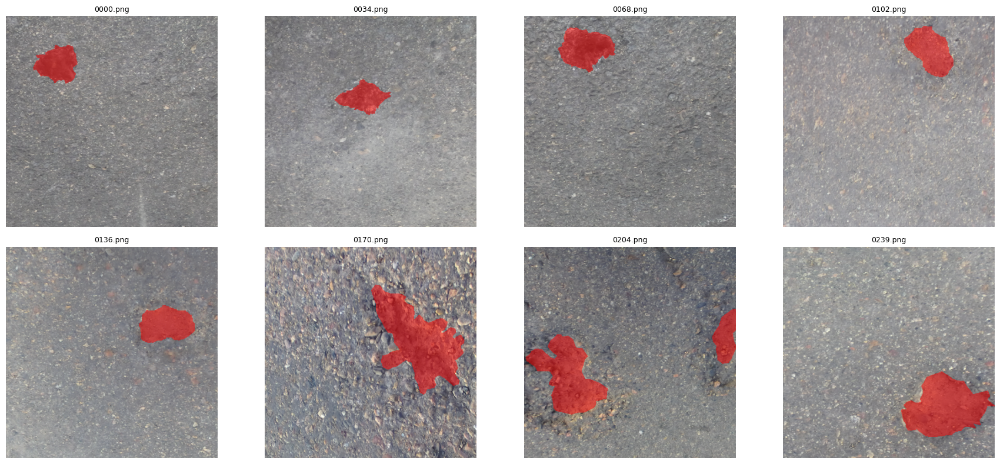

In [4]:
cands = [Path("/kaggle/input/datasets/rangerfan/pothole-600/pothole600"), Path("/kaggle/input/pothole-600/pothole600")]
POTHOLE_DIR = next((p for p in cands if p.exists()), None)
if POTHOLE_DIR is None:
    hits = list(Path("/kaggle/input").rglob("pothole600")); POTHOLE_DIR = hits[0] if hits else None
assert POTHOLE_DIR is not None, "Attach rangerfan/pothole-600 with Add Input"
print("Pothole-600 root:", POTHOLE_DIR)

SPLITS = {"train": "training", "val": "validation", "test": "testing"}
print("\nFile schema:")
for split in SPLITS.values():
    print(" ", split, {s.name: (len(list(s.glob("*"))), sorted({p.suffix for p in s.glob("*")})) for s in sorted((POTHOLE_DIR / split).iterdir()) if s.is_dir()})

rows, sizes, mask_vals, fracs, hashes, thumbs, tmeta = [], Counter(), set(), [], {}, [], []
for key, split in SPLITS.items():
    names = sorted(p.name for p in (POTHOLE_DIR / split / "rgb").glob("*.png"))
    missing = [n for n in names if not (POTHOLE_DIR / split / "label" / n).exists()]
    empty = 0
    for n in names:
        pth = POTHOLE_DIR / split / "rgb" / n
        hashes.setdefault(hashlib.md5(pth.read_bytes()).hexdigest(), []).append(f"{split}/{n}")
        im = Image.open(pth); sizes[im.size] += 1
        thumbs.append(np.asarray(im.convert("L").resize((16, 16)), np.float32).ravel() / 255); tmeta.append(f"{split}/{n}")
        m = np.array(Image.open(POTHOLE_DIR / split / "label" / n).convert("L"))
        mask_vals |= set(np.unique(m).tolist()); f = float((m > 0).mean()); fracs.append(f); empty += int(f == 0)
    rows.append(dict(split=split, n_images=len(names), missing_masks=len(missing), empty_masks=empty))
audit = pd.DataFrame(rows); display(audit); audit.to_csv(RES / "audit_pothole600.csv", index=False)

from scipy.spatial.distance import cdist
D = cdist(np.stack(thumbs), np.stack(thumbs), "cityblock") / 256
ii, jj = np.where(np.triu(D < 0.01, 1))
cross = sum(tmeta[i].split("/")[0] != tmeta[j].split("/")[0] for i, j in zip(ii, jj))
dups = [v for v in hashes.values() if len(v) > 1]
print("\nResolutions (w,h):", dict(sizes), "| annotation type: pixel-wise binary masks")
print("Mask pixel values:", sorted(mask_vals), "-> set CFG['void_value'] only if one of these is an ignore label, not pothole")
print(f"Pothole pixel fraction: mean {np.mean(fracs):.4f}, min {np.min(fracs):.4f}, max {np.max(fracs):.4f}",
      "-> few-pixel defects: consider CFG['loss'] = 'ce_dice' or 'ce_weighted'" if np.mean(fracs) < 0.05 else "")
print(f"Exact-duplicate groups: {len(dups)} | near-duplicate pairs (16x16 L1 < 0.01): {len(ii)}, of which cross-split (leakage risk): {cross}")
print("Calibration: Pothole-600 is used as RGB only; no calibration is needed. Stereo geometry uses RSRD (calibrated).")
print("TODO (report): source, version, license, access conditions; split = dataset's predefined train/val/test; masks cover all visible potholes? (check overlays)")

fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for a, k in zip(ax.ravel(), np.linspace(0, len(ds_names := sorted((POTHOLE_DIR / "training" / "rgb").glob("*.png"))) - 1, 8).astype(int)):
    n = ds_names[k].name
    im = np.array(Image.open(POTHOLE_DIR / "training" / "rgb" / n).convert("RGB")); mk = np.array(Image.open(POTHOLE_DIR / "training" / "label" / n).convert("L")) > 0
    im[mk] = (0.5 * im[mk] + 0.5 * np.array([255, 0, 0])).astype(np.uint8); a.imshow(im); a.set_title(n, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(RES / "audit_overlays.png", dpi=120); plt.show()

### Dataset code (the same code is in the repo's `src/datasets/`)

In [5]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
IGNORE_INDEX = 255          # void pixels: excluded from the loss and from all metrics

class Pothole600(Dataset):
    """RGB image + binary pothole mask (RGB-only, as in the project brief).
    Masks are resized with nearest-neighbour interpolation.
    Training augmentation (moderate): horizontal flip, random 80-100% crop, brightness/contrast jitter."""

    def __init__(self, root, split, size=512, train=False, void_value=None):
        self.d, self.size, self.train, self.void_value = Path(root) / split, size, train, void_value
        self.names = sorted(p.name for p in (self.d / "rgb").glob("*.png"))
        for n in self.names:
            assert (self.d / "label" / n).exists(), f"missing mask for {n}"

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        n = self.names[i]
        rgb = Image.open(self.d / "rgb" / n).convert("RGB")
        m = Image.open(self.d / "label" / n).convert("L")
        if self.train:
            if random.random() < 0.5:
                rgb, m = ImageOps.mirror(rgb), ImageOps.mirror(m)
            if random.random() < 0.5:
                w, h = rgb.size
                s = random.uniform(0.8, 1.0); cw, ch = int(w * s), int(h * s)
                x0, y0 = random.randint(0, w - cw), random.randint(0, h - ch)
                box = (x0, y0, x0 + cw, y0 + ch)
                rgb, m = rgb.crop(box), m.crop(box)
            if random.random() < 0.8:
                rgb = ImageEnhance.Brightness(rgb).enhance(random.uniform(0.8, 1.2))
                rgb = ImageEnhance.Contrast(rgb).enhance(random.uniform(0.8, 1.2))
        s2 = (self.size, self.size)
        rgb = np.asarray(rgb.resize(s2, Image.BILINEAR), np.float32) / 255.0
        m = np.asarray(m.resize(s2, Image.NEAREST))
        y = (m > 0).astype(np.int64)
        if self.void_value is not None:
            y[m == self.void_value] = IGNORE_INDEX
        x = torch.from_numpy(((rgb - MEAN) / STD).transpose(2, 0, 1).copy()).float()
        return {"rgb": x, "mask": torch.from_numpy(y), "name": n}


ds = {k: Pothole600(POTHOLE_DIR, v, CFG["image_size"], train=(k == "train"), void_value=CFG["void_value"]) for k, v in SPLITS.items()}
mk = lambda k, sh: DataLoader(ds[k], batch_size=CFG["batch_size"], shuffle=sh, num_workers=2, pin_memory=True)
train_loader, val_loader, test_loader = mk("train", True), mk("val", False), mk("test", False)
print({k: len(v) for k, v in ds.items()})
b = next(iter(train_loader)); print("rgb", tuple(b["rgb"].shape), "mask", tuple(b["mask"].shape), "mask values", torch.unique(b["mask"]).tolist())

{'train': 240, 'val': 180, 'test': 180}
rgb (8, 3, 512, 512) mask (8, 512, 512) mask values [0, 1]


## Models
One cell per model, so each model can be changed (or removed) without touching the others. The same code lives in the repo's `src/models/`.

### Shared pieces: logits wrapper, patch-embedding helper, stock SegFormer loader

In [7]:
def get_patch_embeds(sf):
    """Return the 4 patch-embedding modules of a SegformerModel (works across transformers versions)."""
    for holder in (sf, getattr(sf, "encoder", None)):
        if holder is None:
            continue
        if hasattr(holder, "stages"):
            return [s.patch_embeddings for s in holder.stages]
        if hasattr(holder, "patch_embeddings"):
            return list(holder.patch_embeddings)
    raise RuntimeError("Unknown SegFormer layout: " + str([n for n, _ in sf.named_children()]))


class SegModel(nn.Module):
    """Thin wrapper so every model returns plain logits: model(x) -> (B, 2, H/4, W/4). No custom logic."""
    def __init__(self, hf):
        super().__init__()
        self.hf = hf
    def forward(self, x):
        return self.hf(pixel_values=x).logits


def build_stock_segformer(pretrained, num_labels=2):
    """Stock Hugging Face SegFormer with pretrained weights and a two-class head (background / pothole)."""
    return SegformerForSemanticSegmentation.from_pretrained(
        pretrained, num_labels=num_labels,
        id2label={0: "background", 1: "pothole"}, label2id={"background": 0, "pothole": 1},
        ignore_mismatched_sizes=True)


count_params = lambda m: sum(p.numel() for p in m.parameters())

### Model 1 — BASELINE: stock SegFormer-B0 (as required by the brief)

In [9]:
def build_baseline(pretrained):
    """MODEL 1 - BASELINE: the stock SegFormer-B0 (RGB input, pretrained weights). Nothing is changed."""
    return SegModel(build_stock_segformer(pretrained))

### Model 2 — NCPR v1: replaces the stride-2 patch-embedding convolutions (kept as a documented earlier version)

In [11]:
class NCPRDownsample(nn.Module):
    """NCPR v1: REPLACES a stride-2 patch-embedding conv by
    2x2 phases -> contrast |phase - mean| -> 1x1 routing conv -> softmax -> weighted sum (H/2, W/2) -> the same conv at stride 1.
    use_contrast=False feeds raw phases to the router instead."""
    def __init__(self, conv, use_contrast=True):
        super().__init__()
        C = conv.in_channels
        self.use_contrast = use_contrast
        self.router = nn.Conv2d(4 * C, 4, 1)
        nn.init.zeros_(self.router.weight); nn.init.zeros_(self.router.bias)    # starts as a plain average of the 4 phases
        self.conv = nn.Conv2d(C, conv.out_channels, conv.kernel_size, stride=1,
                              padding=conv.padding, bias=conv.bias is not None)
        self.conv.load_state_dict(conv.state_dict())

    def forward(self, x):
        H, W = x.shape[-2:]
        if H % 2 or W % 2:
            x = F.pad(x, (0, W % 2, 0, H % 2))
        ph = torch.stack([x[:, :, 0::2, 0::2], x[:, :, 0::2, 1::2],
                          x[:, :, 1::2, 0::2], x[:, :, 1::2, 1::2]], dim=1)          # B,4,C,h,w
        sig = (ph - ph.mean(1, keepdim=True)).abs() if self.use_contrast else ph
        w = torch.softmax(self.router(sig.flatten(1, 2)), dim=1)                      # B,4,h,w
        return self.conv((ph * w.unsqueeze(2)).sum(1))


def build_ncpr_v1(pretrained, use_contrast=True):
    """MODEL 2 - NCPR v1: stock SegFormer-B0 with the stage 2-4 patch-embedding convs replaced by NCPRDownsample."""
    m = SegModel(build_stock_segformer(pretrained))
    pe = get_patch_embeds(m.hf.segformer)
    for i in (1, 2, 3):          # stage 1 is a 7x7 stride-4 stem and is left unchanged
        pe[i].proj = NCPRDownsample(pe[i].proj, use_contrast)
    return m

### Model 3 — PROPOSED: SegFormer-B0 + residual NCPR (keeps the pretrained convolution, adds a zero-initialised contrast-routed branch)

In [14]:
class NCPRResidual(nn.Module):
    """Keeps the pretrained stride-2 conv untouched and ADDS a contrast-routed branch.
    The branch is zero-initialised, so at step 0 the network is identical to the baseline."""
    def __init__(self, conv, use_contrast=True):
        super().__init__()
        C = conv.in_channels
        self.orig, self.use_contrast = conv, use_contrast
        self.router = nn.Conv2d(4 * C, 4, 1)               # phase-routing scores from contrast
        self.mix = nn.Conv2d(C, conv.out_channels, 1)      # maps the routed features to the stage width
        for m in (self.router, self.mix):
            nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        y = self.orig(x)                                    # pretrained path: (B, Cout, H/2, W/2)
        H, W = x.shape[-2:]
        if H % 2 or W % 2:
            x = F.pad(x, (0, W % 2, 0, H % 2))
        ph = torch.stack([x[:, :, 0::2, 0::2], x[:, :, 0::2, 1::2],
                          x[:, :, 1::2, 0::2], x[:, :, 1::2, 1::2]], dim=1)      # B,4,C,h,w
        sig = (ph - ph.mean(1, keepdim=True)).abs() if self.use_contrast else ph
        w = torch.softmax(self.router(sig.flatten(1, 2)), dim=1)                  # B,4,h,w
        return y + self.mix((ph * w.unsqueeze(2)).sum(1))


class ProposedSegFormer(SegModel):
    """MODEL 3 - PROPOSED: stock SegFormer-B0 + residual NCPR in stages 2-4."""
    def __init__(self, pretrained, use_contrast=True):
        super().__init__(build_stock_segformer(pretrained))
        pe = get_patch_embeds(self.hf.segformer)
        for i in (1, 2, 3):
            pe[i].proj = NCPRResidual(pe[i].proj, use_contrast)

    def param_groups(self, lr, new_mult=10.0):
        """New NCPR parameters (zero-initialised) train at 10x lr; pretrained weights keep lr."""
        new = [p for n, p in self.named_parameters() if ".router." in n or ".mix." in n]
        ids = {id(p) for p in new}
        old = [p for p in self.parameters() if id(p) not in ids]
        return [{"params": old, "lr": lr}, {"params": new, "lr": lr * new_mult}]


def build_proposed(pretrained, use_contrast=True):
    return ProposedSegFormer(pretrained, use_contrast)

### Model registry: add / remove models here, and choose which ones to train with `CFG['models_to_run']`

In [15]:
BASE_TAG, PROP_TAG = "baseline", "proposed"
MODEL_BUILDERS = {
    "baseline":            lambda: build_baseline(CFG["pretrained"]),
    "ncpr_v1":             lambda: build_ncpr_v1(CFG["pretrained"]),
    "proposed":            lambda: build_proposed(CFG["pretrained"]),
    "proposed_nocontrast": lambda: build_proposed(CFG["pretrained"], use_contrast=False),   # ablation: router sees raw phases, not contrast
}
ckpt_path = lambda tag, seed: CKPT / f"{tag}_{CFG['loss']}_s{seed}.pth"

def load_model(tag, seed):
    m = MODEL_BUILDERS[tag]().to(DEVICE)
    m.load_state_dict(torch.load(ckpt_path(tag, seed), map_location=DEVICE))
    return m.eval()

# shape check + parameter overhead for the models you will train
xb = next(iter(train_loader))["rgb"].to(DEVICE)
with torch.no_grad():
    for tag in CFG["models_to_run"]:
        m = MODEL_BUILDERS[tag]().to(DEVICE).eval()
        print(f"{tag:20s} params {count_params(m):>10,} | logits {tuple(m(xb).shape)}")
        if hasattr(m, "param_groups"):
            n_new = sum(p.numel() for g in m.param_groups(1.0)[1:] for p in g["params"])
            print(f"{'':20s} new NCPR parameters: {n_new:,} (+{100 * n_new / (count_params(m) - n_new):.2f}% vs baseline)")
        del m
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


baseline             params  3,714,658 | logits (8, 2, 128, 128)


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


proposed             params  3,772,494 | logits (8, 2, 128, 128)
                     new NCPR parameters: 57,836 (+1.56% vs baseline)


### Training, evaluation and inference code

In [16]:
def postprocess(prob, thr=0.5, min_px=0):
    """Probability map -> binary mask; connected components smaller than min_px are removed.
    Note: connected components may merge touching defects."""
    pred = prob > thr
    if min_px > 0 and pred.any():
        n, lab, st, _ = cv2.connectedComponentsWithStats(pred.astype(np.uint8), connectivity=8)
        keep = np.zeros(n, bool); keep[1:] = st[1:, cv2.CC_STAT_AREA] >= min_px
        pred = keep[lab]
    return pred


def seg_metrics(probs, masks, thr=0.5, min_px=0):
    """Global IoU/Dice/precision/recall (void pixels excluded) + per-image IoU (1.0 if both empty)."""
    tp = fp = fn = 0; per = []
    for p, m in zip(probs, masks):
        valid = m != IGNORE_INDEX
        pred = postprocess(p.astype(np.float32), thr, min_px) & valid
        gt = (m == 1) & valid
        t, f_p, f_n = int((pred & gt).sum()), int((pred & ~gt).sum()), int((~pred & gt).sum())
        u = t + f_p + f_n
        per.append(t / u if u > 0 else 1.0)
        tp += t; fp += f_p; fn += f_n
    return dict(iou=tp / (tp + fp + fn + 1e-9), dice=2 * tp / (2 * tp + fp + fn + 1e-9),
                precision=tp / (tp + fp + 1e-9), recall=tp / (tp + fn + 1e-9),
                mean_image_iou=float(np.mean(per))), per


def tune_postprocess(val_probs, val_masks, thrs=(0.3, 0.4, 0.5, 0.6, 0.7), min_pxs=(0, 50, 100, 200, 400)):
    """Choose probability threshold and minimum region size on VALIDATION data only."""
    best = (-1.0, 0.5, 0)
    for t in thrs:
        for mp in min_pxs:
            iou = seg_metrics(val_probs, val_masks, t, mp)[0]["iou"]
            if iou > best[0]:
                best = (iou, t, mp)
    return dict(val_iou=best[0], thr=best[1], min_px=best[2])


def paired_bootstrap(a, b, n=10000, seed=0):
    """Paired bootstrap over test images: mean difference, 95% CI, wins, losses."""
    d = np.asarray(a) - np.asarray(b)
    idx = np.random.default_rng(seed).integers(0, len(d), (n, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return float(d.mean()), float(lo), float(hi), int((d > 0).sum()), int((d < 0).sum())


def seg_loss(logits, m, kind="ce", class_weights=None):
    """kind: 'ce' | 'ce_weighted' | 'ce_dice'. Void pixels (IGNORE_INDEX) never enter the loss."""
    w = torch.tensor(class_weights, device=logits.device, dtype=torch.float32) if (kind == "ce_weighted" and class_weights) else None
    loss = F.cross_entropy(logits, m, weight=w, ignore_index=IGNORE_INDEX)
    if kind == "ce_dice":
        p = logits.softmax(1)[:, 1]; valid = (m != IGNORE_INDEX).float(); g = (m == 1).float()
        inter = (p * g * valid).sum()
        loss = loss + 1 - (2 * inter + 1) / ((p * valid).sum() + (g * valid).sum() + 1)
    return loss


@torch.no_grad()
def collect_probs(model, loader, device, loss_kind="ce", class_weights=None):
    """Pothole probability maps (N,H,W float16), masks (N,H,W uint8, 255=void), names, mean loss."""
    model.eval(); P, M, names, loss_sum, n = [], [], [], 0.0, 0
    for b in loader:
        x, m = b["rgb"].to(device), b["mask"].to(device)
        lg = F.interpolate(model(x), size=m.shape[-2:], mode="bilinear", align_corners=False)
        loss_sum += seg_loss(lg, m, loss_kind, class_weights).item() * x.size(0); n += x.size(0)
        P.append(lg.softmax(1)[:, 1].half().cpu()); M.append(m.to(torch.uint8).cpu()); names += list(b["name"])
    return torch.cat(P).numpy(), torch.cat(M).numpy(), names, loss_sum / n


def train_model(model, train_loader, val_loader, cfg, device, ckpt_path, tag=""):
    """Fine-tune; keep the best-validation-IoU checkpoint; return model with those weights."""
    opt = torch.optim.AdamW(model.param_groups(cfg["lr"]) if hasattr(model, "param_groups") else model.parameters(),
                            lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    best, best_ep, hist = -1.0, 0, []
    for ep in range(cfg["epochs"]):
        model.train(); tl = n = 0
        for b in train_loader:
            x, m = b["rgb"].to(device), b["mask"].to(device)
            opt.zero_grad(set_to_none=True)
            lg = F.interpolate(model(x), size=m.shape[-2:], mode="bilinear", align_corners=False)
            loss = seg_loss(lg, m, cfg["loss"], cfg.get("class_weights")); loss.backward(); opt.step()
            tl += loss.item() * x.size(0); n += x.size(0)
        P, M, _, vl = collect_probs(model, val_loader, device, cfg["loss"], cfg.get("class_weights"))
        v, _ = seg_metrics(P, M)
        hist.append(dict(epoch=ep + 1, train_loss=tl / n, val_loss=vl, val_iou=v["iou"], val_dice=v["dice"]))
        print(f"{tag} ep{ep+1:02d} | train loss {tl/n:.4f} | val loss {vl:.4f} | val IoU {v['iou']:.4f}")
        if v["iou"] > best:
            best, best_ep = v["iou"], ep + 1; torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, hist, best_ep


@torch.no_grad()
def predict_prob_fullres(model, img_rgb, device, size=512):
    """uint8 RGB image of any size -> pothole probability map at the original resolution."""
    model.eval(); h, w = img_rgb.shape[:2]
    x = (cv2.resize(img_rgb, (size, size), interpolation=cv2.INTER_LINEAR).astype(np.float32) / 255 - MEAN) / STD
    x = torch.from_numpy(x.transpose(2, 0, 1).copy()).float()[None].to(device)
    lg = F.interpolate(model(x), size=(h, w), mode="bilinear", align_corners=False)
    return F.softmax(lg, 1)[0, 1].cpu().numpy()

## 8. Segmentation experiments (Pothole-600)
All models share the pretrained weights, optimizer, epochs, augmentation, loss and seeds. Each (model, seed) keeps the best-validation-IoU checkpoint. Probability threshold and minimum region size are tuned on **validation** data and then applied once to the test split. Results are saved after every run and resume automatically.

In [19]:
# Resume helper (safe to run; does nothing if there is nothing to migrate).
# Older notebook versions called the first NCPR (replaces the conv, 3,718,766 params) "ncpr" and the residual one (3,772,494 params) "ncpr" too.
RESULTS_JSON = RES / "segmentation_results.json"
if RESULTS_JSON.exists():
    res, new_name = json.load(open(RESULTS_JSON)), {3718766: "ncpr_v1", 3772494: "proposed"}
    for r in res:
        if r["model"] == "ncpr" and r["params"] in new_name:
            old, new, seed, loss = "ncpr", new_name[r["params"]], r["seed"], r["loss"]
            for a, b_ in [(CKPT / f"{old}_{loss}_s{seed}.pth", CKPT / f"{new}_{loss}_s{seed}.pth")] + \
                         [(RES / f"per_image_iou_{k}_{old}_s{seed}.npy", RES / f"per_image_iou_{k}_{new}_s{seed}.npy") for k in ("default", "tuned")]:
                if a.exists(): a.rename(b_)
            r["model"] = new
    json.dump(res, open(RESULTS_JSON, "w"))
    print("models already in results:", sorted({(r["model"], r["seed"]) for r in res}))

In [20]:
RESULTS_JSON = RES / "segmentation_results.json"
results = json.load(open(RESULTS_JSON)) if RESULTS_JSON.exists() else []
done = {(r["model"], r["seed"], r["loss"]) for r in results}
json.dump(CFG, open(RES / "config.json", "w"), indent=2)

for seed in CFG["seeds"]:
    for tag in CFG["models_to_run"]:
        if (tag, seed, CFG["loss"]) in done:
            print("skip (done):", tag, seed); continue
        set_seed(seed); t0 = time.time()
        model = MODEL_BUILDERS[tag]().to(DEVICE)
        model, hist, best_ep = train_model(model, train_loader, val_loader, CFG, DEVICE, ckpt_path(tag, seed), tag=f"{tag} s{seed}")
        Pv, Mv, _, _ = collect_probs(model, val_loader, DEVICE, CFG["loss"], CFG["class_weights"])
        tuned = tune_postprocess(Pv, Mv)                                   # chosen on VALIDATION only
        Pt, Mt, names, _ = collect_probs(model, test_loader, DEVICE, CFG["loss"], CFG["class_weights"])
        m_def, per_def = seg_metrics(Pt, Mt, 0.5, 0)
        m_tun, per_tun = seg_metrics(Pt, Mt, tuned["thr"], tuned["min_px"])
        results.append(dict(model=tag, seed=seed, loss=CFG["loss"], best_epoch=best_ep, params=count_params(model),
                            train_minutes=(time.time() - t0) / 60, tuned=tuned, test_default=m_def, test_tuned=m_tun, history=hist))
        np.save(RES / f"per_image_iou_default_{tag}_s{seed}.npy", np.array(per_def)); np.save(RES / f"per_image_iou_tuned_{tag}_s{seed}.npy", np.array(per_tun))
        json.dump(names, open(RES / "test_names.json", "w")); json.dump(results, open(RESULTS_JSON, "w"))
        print(f"==> {tag} s{seed}: test IoU {m_def['iou']:.4f} (thr 0.5) | {m_tun['iou']:.4f} (val-tuned thr {tuned['thr']}, min_px {tuned['min_px']})")
        del model; gc.collect(); torch.cuda.empty_cache()

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


baseline s42 ep01 | train loss 0.5502 | val loss 0.3172 | val IoU 0.2478
baseline s42 ep02 | train loss 0.4111 | val loss 0.2500 | val IoU 0.4577
baseline s42 ep03 | train loss 0.3172 | val loss 0.2461 | val IoU 0.5142
baseline s42 ep04 | train loss 0.2504 | val loss 0.1993 | val IoU 0.4777
baseline s42 ep05 | train loss 0.2106 | val loss 0.1507 | val IoU 0.4715
baseline s42 ep06 | train loss 0.1808 | val loss 0.1360 | val IoU 0.5451
baseline s42 ep07 | train loss 0.1600 | val loss 0.1172 | val IoU 0.5346
baseline s42 ep08 | train loss 0.1441 | val loss 0.1261 | val IoU 0.5348
baseline s42 ep09 | train loss 0.1297 | val loss 0.1017 | val IoU 0.5366
baseline s42 ep10 | train loss 0.1238 | val loss 0.1094 | val IoU 0.5329
baseline s42 ep11 | train loss 0.1091 | val loss 0.0893 | val IoU 0.5522
baseline s42 ep12 | train loss 0.1009 | val loss 0.0784 | val IoU 0.5509
baseline s42 ep13 | train loss 0.0972 | val loss 0.0966 | val IoU 0.5514
baseline s42 ep14 | train loss 0.0885 | val loss 0.

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

... (14 outputs left out)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


proposed s44 ep01 | train loss 0.5435 | val loss 0.3582 | val IoU 0.3920
proposed s44 ep02 | train loss 0.3935 | val loss 0.2607 | val IoU 0.4746
proposed s44 ep03 | train loss 0.2971 | val loss 0.2323 | val IoU 0.4652
proposed s44 ep04 | train loss 0.2353 | val loss 0.2081 | val IoU 0.4328
proposed s44 ep05 | train loss 0.1971 | val loss 0.1506 | val IoU 0.4348
proposed s44 ep06 | train loss 0.1756 | val loss 0.1576 | val IoU 0.4736
proposed s44 ep07 | train loss 0.1512 | val loss 0.1515 | val IoU 0.4797
proposed s44 ep08 | train loss 0.1386 | val loss 0.1369 | val IoU 0.4768
proposed s44 ep09 | train loss 0.1249 | val loss 0.1136 | val IoU 0.5413
proposed s44 ep10 | train loss 0.1119 | val loss 0.1393 | val IoU 0.4464
proposed s44 ep11 | train loss 0.1038 | val loss 0.1294 | val IoU 0.4604
proposed s44 ep12 | train loss 0.0960 | val loss 0.1304 | val IoU 0.4389
proposed s44 ep13 | train loss 0.0931 | val loss 0.0982 | val IoU 0.4982
proposed s44 ep14 | train loss 0.0851 | val loss 0.

default_iou         default_dice         default_precision          \
                mean     std         mean     std              mean     std   
model                                                                         
baseline      0.6158  0.0110       0.7622  0.0085            0.7641  0.0096   
proposed      0.6240  0.0026       0.7685  0.0020            0.7962  0.0291   

         default_recall         tuned_iou         tuned_dice          \
                   mean     std      mean     std       mean     std   
model                                                                  
baseline         0.7605  0.0193    0.6150  0.0124     0.7615  0.0095   
proposed         0.7440  0.0298    0.6249  0.0030     0.7692  0.0023   

         tuned_precision         tuned_recall          
                    mean     std         mean     std  
model                                                  
baseline          0.7736  0.0210       0.7512  0.0351  
proposed          0.7967  0.0069       0.7436  0.0092

,model,seed,best_epoch,params,thr,min_px,default_iou,default_dice,default_precision,default_recall,default_mean_image_iou,tuned_iou,tuned_dice,tuned_precision,tuned_recall,tuned_mean_image_iou
0,baseline,42,18,3714658,0.5,50,0.6249,0.7691,0.7720,0.7663,0.6867,0.6249,0.7691,0.7720,0.7663,0.6867
1,proposed,42,19,3772494,0.4,400,0.6227,0.7675,0.8203,0.7211,0.6924,0.6243,0.7687,0.7917,0.7469,0.6858
2,baseline,43,11,3714658,0.5,400,0.6190,0.7647,0.7533,0.7763,0.6714,0.6190,0.7647,0.7534,0.7763,0.6714
3,proposed,43,20,3772494,0.5,200,0.6223,0.7672,0.8045,0.7331,0.6886,0.6223,0.7672,0.8045,0.7331,0.6886
4,baseline,44,15,3714658,0.6,100,0.6035,0.7527,0.7670,0.7390,0.6825,0.6011,0.7509,0.7954,0.7110,0.6857
5,proposed,44,18,3772494,0.6,400,0.6270,0.7707,0.7639,0.7777,0.6891,0.6282,0.7717,0.7938,0.7507,0.6968


default = threshold 0.5, no region filtering | tuned = threshold and min region size chosen on the validation split
proposed: +57,836 parameters (1.557% of the baseline)


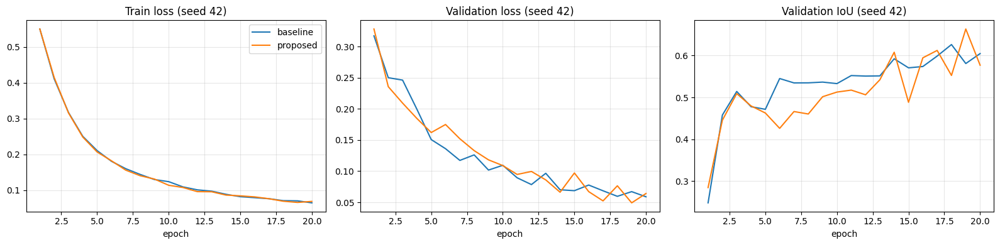

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


baseline     11.8 ms per 512x512 image (GPU timing is noisy; do not claim small speed differences)


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


proposed     12.2 ms per 512x512 image (GPU timing is noisy; do not claim small speed differences)


In [21]:
results = [r for r in json.load(open(RESULTS_JSON)) if r["loss"] == CFG["loss"]]
present = sorted({r["model"] for r in results})
flat = pd.DataFrame([dict(model=r["model"], seed=r["seed"], best_epoch=r["best_epoch"], params=r["params"], thr=r["tuned"]["thr"], min_px=r["tuned"]["min_px"],
                          **{f"default_{k}": v for k, v in r["test_default"].items()}, **{f"tuned_{k}": v for k, v in r["test_tuned"].items()}) for r in results])
metric_cols = [f"{p}_{m}" for p in ("default", "tuned") for m in ("iou", "dice", "precision", "recall")]
summary = flat.groupby("model")[metric_cols].agg(["mean", "std"]).round(4)
display(summary); display(flat.round(4))
summary.to_csv(RES / "segmentation_summary.csv"); flat.to_csv(RES / "segmentation_runs.csv", index=False)
print("default = threshold 0.5, no region filtering | tuned = threshold and min region size chosen on the validation split")

p = flat.groupby("model")["params"].first()
for tag in present:
    if tag != BASE_TAG and BASE_TAG in p.index:
        print(f"{tag}: +{p[tag] - p[BASE_TAG]:,} parameters ({100 * (p[tag] - p[BASE_TAG]) / p[BASE_TAG]:.3f}% of the baseline)")
if len(CFG["seeds"]) < 3:
    print("NOTE: fewer than 3 seeds -> report the proposed model as PRELIMINARY.")

s0 = CFG["seeds"][0]
TUNED = {r["model"]: r["tuned"] for r in results if r["seed"] == s0}          # val-tuned thresholds (seed s0), used below
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for r in [r for r in results if r["seed"] == s0]:
    h = pd.DataFrame(r["history"])
    ax[0].plot(h.epoch, h.train_loss, label=r["model"]); ax[1].plot(h.epoch, h.val_loss, label=r["model"]); ax[2].plot(h.epoch, h.val_iou, label=r["model"])
for a, t in zip(ax, ["Train loss", "Validation loss", "Validation IoU"]):
    a.set_title(t + f" (seed {s0})"); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(); plt.tight_layout(); plt.savefig(RES / "training_curves.png", dpi=120); plt.show()

def time_model(model, n=100):
    x = torch.randn(1, 3, 512, 512, device=DEVICE)
    with torch.no_grad():
        for _ in range(20): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n * 1000
for tag in (BASE_TAG, PROP_TAG):
    if tag in present:
        m = load_model(tag, s0); print(f"{tag:10s} {time_model(m):6.1f} ms per 512x512 image (GPU timing is noisy; do not claim small speed differences)"); del m
torch.cuda.empty_cache()

seed 42: proposed - baseline: mean per-image IoU -0.0009  95% CI [-0.0085, +0.0062]  better on 98 / worse on 82 images
seed 43: proposed - baseline: mean per-image IoU +0.0171  95% CI [+0.0097, +0.0245]  better on 118 / worse on 62 images
seed 44: proposed - baseline: mean per-image IoU +0.0111  95% CI [+0.0054, +0.0173]  better on 97 / worse on 83 images
A CI that includes 0 means the difference is not established. The bootstrap covers test-set sampling only; seed-to-seed variance is in the mean +- std table above.


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


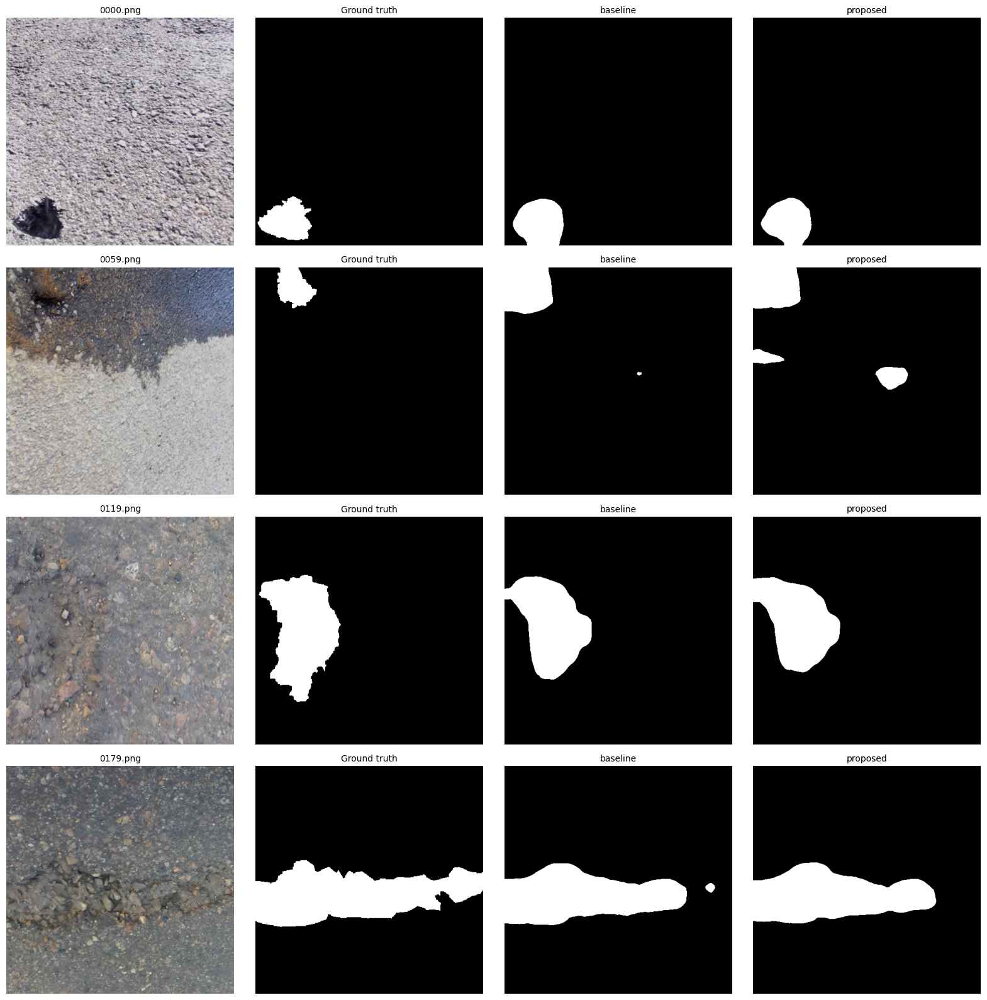

proposed: images with IoU < 0.5: 25 / 180 | IoU == 0 (missed): 0


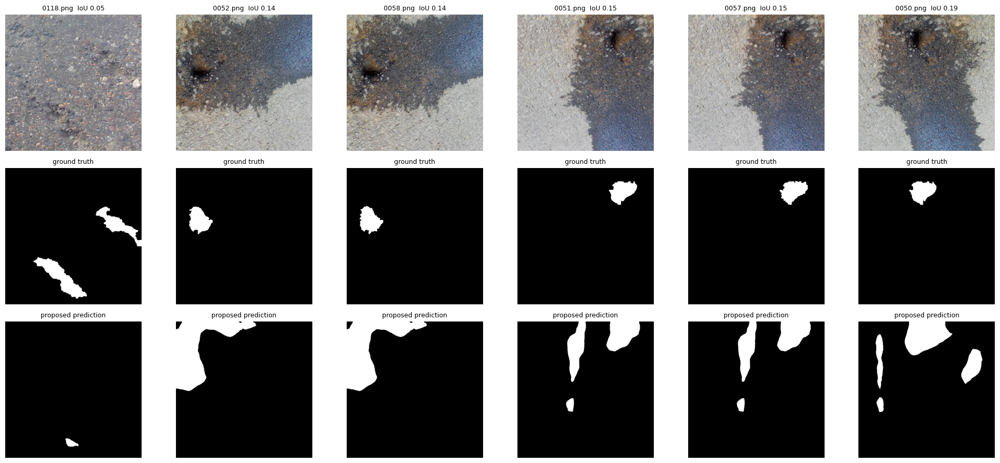

TODO (report): for each failure, name the cause: ambiguous/partial label / small pothole / shadow / water / unannotated defect / boundary error. Connected components may merge touching defects.


In [22]:
# Paired bootstrap on per-image test IoU (val-tuned post-processing), every model vs the baseline, per seed
for seed in CFG["seeds"]:
    base = np.load(RES / f"per_image_iou_tuned_{BASE_TAG}_s{seed}.npy")
    for tag in present:
        f = RES / f"per_image_iou_tuned_{tag}_s{seed}.npy"
        if tag == BASE_TAG or not f.exists(): continue
        d, lo, hi, w, l = paired_bootstrap(np.load(f), base)
        print(f"seed {seed}: {tag} - {BASE_TAG}: mean per-image IoU {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  better on {w} / worse on {l} images")
print("A CI that includes 0 means the difference is not established. The bootstrap covers test-set sampling only; seed-to-seed variance is in the mean +- std table above.")

# Qualitative comparison + failure analysis (seed s0): baseline vs proposed
names = json.load(open(RES / "test_names.json")); probs = {}
for tag in (BASE_TAG, PROP_TAG):
    m = load_model(tag, s0); probs[tag], Mt, _, _ = collect_probs(m, test_loader, DEVICE, CFG["loss"], CFG["class_weights"]); del m
torch.cuda.empty_cache()
load_rgb = lambda n: np.array(Image.open(POTHOLE_DIR / "testing" / "rgb" / n).convert("RGB").resize((512, 512)))
fig, ax = plt.subplots(4, 4, figsize=(16, 16))
for i, k in enumerate(np.linspace(0, len(names) - 1, 4).astype(int)):
    items = [("RGB", load_rgb(names[k])), ("Ground truth", Mt[k] == 1)] + [(t, postprocess(probs[t][k].astype(np.float32), TUNED[t]["thr"], TUNED[t]["min_px"])) for t in (BASE_TAG, PROP_TAG)]
    for a, (t, im) in zip(ax[i], items):
        a.imshow(im, cmap=None if t == "RGB" else "gray"); a.set_title(t if t != "RGB" else names[k], fontsize=10); a.axis("off")
plt.tight_layout(); plt.savefig(RES / "qualitative_segmentation.png", dpi=110); plt.show()

per = np.load(RES / f"per_image_iou_tuned_{PROP_TAG}_s{s0}.npy"); worst = np.argsort(per)[:6]
print(f"{PROP_TAG}: images with IoU < 0.5: {(per < 0.5).sum()} / {len(per)} | IoU == 0 (missed): {(per == 0).sum()}")
fig, ax = plt.subplots(3, 6, figsize=(20, 9))
for j, k in enumerate(worst):
    pr = postprocess(probs[PROP_TAG][k].astype(np.float32), TUNED[PROP_TAG]["thr"], TUNED[PROP_TAG]["min_px"])
    for a, im, t in zip(ax[:, j], [load_rgb(names[k]), Mt[k] == 1, pr], [f"{names[k]}  IoU {per[k]:.2f}", "ground truth", f"{PROP_TAG} prediction"]):
        a.imshow(im, cmap=None if t.startswith(names[k]) else "gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(RES / "segmentation_failures.png", dpi=110); plt.show()
print("TODO (report): for each failure, name the cause: ambiguous/partial label / small pothole / shadow / water / unannotated defect / boundary error. Connected components may merge touching defects.")

## 9. Stereo geometry experiments (RSRD, evaluated separately from segmentation)
(a) calibration and unit checks, (b) disparity **estimation** with a pretrained stereo model vs the reference, (c) road-plane fitting and measurements (unit-tested on synthetic data).

In [23]:
RSRD_URL = "https://api.figshare.com/v2/file/download/44667559"
RSRD_DIR, ZIP_PATH = Path("/kaggle/working/RSRD"), Path("/kaggle/working/RSRD.zip")
NEED = ("left", "depth", "disparity")
have = all((RSRD_DIR / "test" / f).is_dir() and any((RSRD_DIR / "test" / f).iterdir()) for f in NEED)
if not have:
    import requests
    if not ZIP_PATH.exists():
        r = requests.get(RSRD_URL, stream=True, timeout=(60, 300)); r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        print(f"Archive {total/1024**3:.2f} GB | free {shutil.disk_usage('/kaggle/working').free/1024**3:.2f} GB")
        with open(ZIP_PATH, "wb") as f, tqdm(total=total, unit="B", unit_scale=True) as pb:
            for ch in r.iter_content(8 * 1024 * 1024):
                f.write(ch); pb.update(len(ch))
    with zipfile.ZipFile(ZIP_PATH) as z:
        sel = [m for m in z.infolist() if not m.is_dir() and m.filename.startswith("RSRD-dense/test/") and any(f"/{f}/" in m.filename for f in NEED)]
        for m in tqdm(sel, desc="extract"):
            dst = RSRD_DIR / Path(m.filename).relative_to("RSRD-dense"); dst.parent.mkdir(parents=True, exist_ok=True)
            with z.open(m) as s, open(dst, "wb") as t: shutil.copyfileobj(s, t)

TOOLKIT = RSRD_DIR / "RSRD_dev_toolkit"
if not TOOLKIT.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ztsrxh/RSRD_dev_toolkit.git", str(TOOLKIT)], check=True)
calibs, calib_files = {}, {}
for p in sorted((TOOLKIT / "calibration_files").glob("calib_*.pkl")):
    if "_half" not in p.stem:
        calibs[p.stem.replace("calib_", "")] = pickle.load(open(p, "rb")); calib_files[p.stem.replace("calib_", "")] = str(p)

T = RSRD_DIR / "test"
find = lambda folder, stem: next((T / folder).glob(stem + ".*"))
stems = {f: {p.stem for p in (T / f).glob("*") if p.is_file()} for f in NEED}
FRAMES = sorted(stems["left"] & stems["depth"] & stems["disparity"])
dates = Counter(s[:8] for s in FRAMES)
print("matching left/depth/disparity frames:", len(FRAMES), "| recording dates:", dict(dates))
assert all(d in calibs for d in dates), f"missing calibration for {set(dates) - set(calibs)}"
for d in dates:
    c = calibs[d]; K = np.asarray(c["K"])
    print(d, f"fx={K[0,0]:.1f} fy={K[1,1]:.1f} cx={K[0,2]:.1f} cy={K[1,2]:.1f} | baseline={float(c['B']):.2f} (stored in mm, used in m) | image {c['Width']}x{c['Height']}")
print("TODO (report): RSRD source/version/license, calibration source (RSRD dev toolkit), test split used, rectification assumption (verify on the dataset page).")

def read16(path):
    return cv2.imread(str(path), cv2.IMREAD_UNCHANGED).astype(np.float32) / 256.0      # 16-bit png, scale 256

def frame_geometry(stem):
    c = calibs[stem[:8]]; return np.asarray(c["K"], dtype=np.float64), float(c["B"]) / 1000.0, read16(find("disparity", stem))

def load_left(stem):
    return cv2.cvtColor(cv2.imread(str(next((T / "left").glob(stem + ".*")))), cv2.COLOR_BGR2RGB)

def ensure_right(stems_):
    have_r = {p.stem for p in (T / "right").glob("*")} if (T / "right").exists() else set()
    need = {s for s in stems_ if s not in have_r}
    if not need: return
    with zipfile.ZipFile(ZIP_PATH) as z:
        for m in z.infolist():
            if not m.is_dir() and m.filename.startswith("RSRD-dense/test/") and "/right/" in m.filename and Path(m.filename).stem in need:
                dst = RSRD_DIR / Path(m.filename).relative_to("RSRD-dense"); dst.parent.mkdir(parents=True, exist_ok=True)
                with z.open(m) as s, open(dst, "wb") as t: shutil.copyfileobj(s, t)

def load_right(stem):
    ensure_right([stem]); return cv2.cvtColor(cv2.imread(str(next((T / "right").glob(stem + ".*")))), cv2.COLOR_BGR2RGB)

Archive 15.12 GB | free 19.41 GB


  0%|          | 0.00/16.2G [00:00<?, ?B/s]

extract:   0%|          | 0/900 [00:00<?, ?it/s]

Cloning into '/kaggle/working/RSRD/RSRD_dev_toolkit'...


matching left/depth/disparity frames: 300 | recording dates: {'20230317': 23, '20230321': 10, '20230406': 23, '20230408': 120, '20230409': 124}
20230317 fx=2024.5 fy=2024.5 cx=1033.4 cy=498.6 | baseline=118.81 (stored in mm, used in m) | image 1920x1080
20230321 fx=2024.5 fy=2024.5 cx=1033.4 cy=498.6 | baseline=118.81 (stored in mm, used in m) | image 1920x1080
20230406 fx=2022.6 fy=2022.6 cx=1037.4 cy=500.8 | baseline=118.79 (stored in mm, used in m) | image 1920x1080
20230408 fx=2022.6 fy=2022.6 cx=1037.4 cy=500.8 | baseline=118.79 (stored in mm, used in m) | image 1920x1080
20230409 fx=2022.6 fy=2022.6 cx=1037.4 cy=500.8 | baseline=118.79 (stored in mm, used in m) | image 1920x1080
TODO (report): RSRD source/version/license, calibration source (RSRD dev toolkit), test split used, rectification assumption (verify on the dataset page).


In [24]:
def disparity_to_depth(disp, fx_px, baseline_m, min_disp=0.5):
    """Z = f * B / d, with f in PIXELS, B in METRES, d in PIXELS. Invalid disparity -> depth 0."""
    z = np.zeros(disp.shape, dtype=np.float32)
    ok = np.isfinite(disp) & (disp > min_disp)
    z[ok] = fx_px * baseline_m / disp[ok]
    return z


def sgbm_disparity(left_rgb, right_rgb):
    """Classical OpenCV SGBM fallback. Inputs must be RECTIFIED. Returns disparity in pixels."""
    g = lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    sg = cv2.StereoSGBM_create(minDisparity=0, numDisparities=256, blockSize=5, P1=8 * 25, P2=32 * 25,
                               uniquenessRatio=10, speckleWindowSize=100, speckleRange=2,
                               mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    return sg.compute(g(left_rgb), g(right_rgb)).astype(np.float32) / 16.0


def setup_raft_stereo(root="/kaggle/working/RAFT-Stereo"):
    """Clone the official RAFT-Stereo repo and download its pretrained weights with the authors' script (needs Internet)."""
    import subprocess
    from pathlib import Path
    root = Path(root)
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/princeton-vl/RAFT-Stereo", str(root)], check=True)
    if not (root / "models" / "raftstereo-middlebury.pth").exists():
        subprocess.run("bash download_models.sh", shell=True, cwd=root, check=True)
    return root


def raft_stereo_disparity(left_rgb, right_rgb, device=None, scale=0.5, repo="/kaggle/working/RAFT-Stereo",
                          ckpt="raftstereo-middlebury.pth", iters=32):
    """Pretrained RAFT-Stereo (official princeton-vl code + weights), run as a subprocess at `scale` x resolution
    (full-resolution pairs exceed T4 memory). The disparity is rescaled back to full-resolution pixels."""
    import subprocess, sys, tempfile
    from pathlib import Path
    root = setup_raft_stereo(repo)
    H, W = left_rgb.shape[:2]; h, w = int(H * scale), int(W * scale)
    with tempfile.TemporaryDirectory() as td:
        td = Path(td)
        for name, im in (("left", left_rgb), ("right", right_rgb)):
            small = cv2.resize(im, (w, h), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(td / f"{name}.png"), cv2.cvtColor(small, cv2.COLOR_RGB2BGR))
        cmd = [sys.executable, "demo.py", "--restore_ckpt", f"models/{ckpt}", "--corr_implementation", "alt", "--mixed_precision",
               "--valid_iters", str(iters), "-l", str(td / "left.png"), "-r", str(td / "right.png"),
               "--output_directory", str(td / "out"), "--save_numpy"]
        r = subprocess.run(cmd, cwd=root, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(r.stderr[-600:])
        d = np.load(next((td / "out").glob("*.npy"))).astype(np.float32)
    if np.median(d) < 0:                          # the demo saves negative disparity; make it positive
        d = -d
    return cv2.resize(d, (W, H), interpolation=cv2.INTER_LINEAR) * (W / w)


def estimate_disparity(left_rgb, right_rgb, device=None, method="raft"):
    """Returns (disparity_px, method_name). Falls back to SGBM if the pretrained model cannot run."""
    if method == "raft":
        try:
            return raft_stereo_disparity(left_rgb, right_rgb, device), "RAFT-Stereo (official princeton-vl code + pretrained weights)"
        except Exception as e:
            print("RAFT-Stereo failed ->", repr(e)[-600:], "-> using SGBM fallback")
    return sgbm_disparity(left_rgb, right_rgb), "OpenCV SGBM (classical fallback)"

In [46]:
# (a) UNIT / CONSISTENCY CHECK: reference disparity -> depth vs reference depth. Validates units, focal length (px) and baseline (m).
# It is NOT an accuracy test of a stereo estimator (that is (b) below).
s_abs = s_sq = 0.0; n_px = 0; rows = []
for stem in tqdm(FRAMES, desc="unit check"):
    K, Bm, disp = frame_geometry(stem); gt = read16(find("depth", stem))
    z = disparity_to_depth(disp, K[0, 0], Bm); v = (z > 0) & (gt > 0); e = z[v] - gt[v]
    s_abs += np.abs(e).sum(); s_sq += (e ** 2).sum(); n_px += v.sum()
    rows.append(dict(sample_id=stem, ref_depth_valid_fraction=float((gt > 0).mean()), mae_m=float(np.abs(e).mean()) if v.any() else None))
print(f"frames {len(FRAMES)} | valid pixels {n_px:,} | MAE {s_abs/n_px:.4f} m | RMSE {np.sqrt(s_sq/n_px):.4f} m")
print(f"reference depth coverage per frame: {np.mean([r['ref_depth_valid_fraction'] for r in rows]):.3%} (sparse -> many defects will lack valid depth)")
pd.DataFrame(rows).to_csv(RES / "rsrd_unit_check.csv", index=False)

# (b) STEREO ESTIMATION vs reference on a few rectified pairs (pretrained RAFT-Stereo; SGBM fallback)
N_STEREO = 8
chosen = FRAMES[:: max(1, len(FRAMES) // N_STEREO)][:N_STEREO]; ensure_right(chosen)
DISP_EST_DIR = RES / "rsrd_disp_est"; DISP_EST_DIR.mkdir(exist_ok=True); STEREO_METHOD = {}
def get_estimated_disparity(stem):
    f = DISP_EST_DIR / f"{stem}.npy"
    if f.exists(): return np.load(f)
    d, STEREO_METHOD["name"] = estimate_disparity(load_left(stem), load_right(stem), DEVICE); np.save(f, d.astype(np.float32)); return d

ev = []
for stem in tqdm(chosen, desc="stereo estimation"):
    K, Bm, gt = frame_geometry(stem); est = get_estimated_disparity(stem)
    g = gt > 0; v = g & (est > 0.5); err = np.abs(est[v] - gt[v])
    zE, zG = disparity_to_depth(est, K[0, 0], Bm)[v], disparity_to_depth(gt, K[0, 0], Bm)[v]
    ev.append(dict(sample_id=stem, est_valid_coverage=float(v.sum() / g.sum()), EPE_px=float(err.mean()),
                   D1_bad=float(((err > 3) & (err > 0.05 * gt[v])).mean()), depth_MAE_m=float(np.abs(zE - zG).mean()), depth_RMSE_m=float(np.sqrt(((zE - zG) ** 2).mean()))))
ev = pd.DataFrame(ev); display(ev.round(3)); print("method:", STEREO_METHOD.get("name", "cached")); print(ev.drop(columns="sample_id").mean().round(3).to_dict())
ev.to_csv(RES / "rsrd_stereo_estimation_eval.csv", index=False)

unit check:   0%|          | 0/300 [00:00<?, ?it/s]

frames 300 | valid pixels 25,257,491 | MAE 0.0022 m | RMSE 0.0025 m
reference depth coverage per frame: 4.060% (sparse -> many defects will lack valid depth)


stereo estimation:   0%|          | 0/8 [00:00<?, ?it/s]

,sample_id,est_valid_coverage,EPE_px,D1_bad,depth_MAE_m,depth_RMSE_m
0,20230317074848.400,1.0,0.564,0.018,0.046,0.120
1,20230406013950.400,1.0,0.696,0.024,0.061,0.150
2,20230408031252.000,1.0,0.735,0.017,0.092,0.188
3,20230408031627.200,1.0,0.879,0.017,0.073,0.146
4,20230408042104.200,1.0,1.029,0.020,0.140,0.225
5,20230409020034.200,1.0,1.117,0.024,0.262,0.361
6,20230409020948.400,1.0,1.075,0.024,0.131,0.241
7,20230409021734.400,1.0,0.920,0.025,0.115,0.196


method: cached
{'est_valid_coverage': 1.0, 'EPE_px': 0.877, 'D1_bad': 0.021, 'depth_MAE_m': 0.115, 'depth_RMSE_m': 0.203}


In [36]:
# ---- Road-plane fitting and pothole measurement (all outputs in metres) ----
SEVERITY_BINS_M = [(0.02, "low"), (0.05, "medium"), (float("inf"), "high")]   # ASSUMED thresholds, not a standard


def backproject(depth, K):
    h, w = depth.shape
    u, v = np.meshgrid(np.arange(w), np.arange(h))
    X = (u - K[0, 2]) * depth / K[0, 0]
    Y = (v - K[1, 2]) * depth / K[1, 1]
    return np.stack([X, Y, depth], axis=-1)


def fit_plane_ransac(pts, iters=300, thresh=0.01, seed=0):
    """Plane n.p + d = 0 with |n| = 1, oriented so the camera (origin) has d > 0."""
    if len(pts) < 100:
        return None
    rng = np.random.default_rng(seed)
    best_inl, best_n = None, -1
    for _ in range(iters):
        s = pts[rng.choice(len(pts), 3, replace=False)]
        n = np.cross(s[1] - s[0], s[2] - s[0])
        nn_ = np.linalg.norm(n)
        if nn_ < 1e-9:
            continue
        n = n / nn_
        inl = np.abs(pts @ n - n @ s[0]) < thresh
        if inl.sum() > best_n:
            best_n, best_inl = inl.sum(), inl
    if best_inl is None:
        return None
    P = pts[best_inl]
    c = P.mean(0)
    n = np.linalg.svd(P - c, full_matrices=False)[2][-1]
    d = -n @ c
    if d < 0:
        n, d = -n, -d
    return n, d, best_inl


def severity_from_depth(depth_p95_m):
    for limit, name in SEVERITY_BINS_M:
        if depth_p95_m < limit:
            return name


def measure_defect(depth, mask, K, ring_px=60, min_valid_frac=0.1, min_mask_pts=30,
                   min_road_pts=500, max_fit_err_m=0.01, min_depth_snr=3.0):
    """depth: HxW metres (0/NaN = invalid, may be sparse). mask: HxW bool (one connected defect).
    Depth is measured relative to a plane fitted to the road ring around the defect.
    Returns a dict; if anything is unreliable the severity stays None (never invented)."""
    out = dict(depth_p95_m=None, area_m2=None, volume_m3=None, severity=None,
               measurement_status="unavailable", reason="",
               valid_geometry_fraction=None, surface_fit_error_m=None)
    mask = mask.astype(bool)
    if mask.sum() == 0:
        out["reason"] = "empty mask"; return out
    valid = np.isfinite(depth) & (depth > 0)
    nvalid = int((valid & mask).sum())
    out["valid_geometry_fraction"] = float(nvalid / mask.sum())
    if nvalid < min_mask_pts or out["valid_geometry_fraction"] < min_valid_frac:
        out["reason"] = "too few valid depth pixels inside defect"; return out

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * ring_px + 1, 2 * ring_px + 1))
    near = cv2.dilate(mask.astype(np.uint8), k).astype(bool)
    skip = cv2.dilate(mask.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
    road = near & ~skip & valid
    if road.sum() < min_road_pts:
        out["reason"] = "not enough road depth pixels around defect"; return out

    P = backproject(np.where(valid, depth, 0.0), K)
    fit = fit_plane_ransac(P[road])
    if fit is None:
        out["reason"] = "plane fit failed"; return out
    n, d, inl = fit
    fit_err = float(np.sqrt(((P[road][inl] @ n + d) ** 2).mean()))
    out["surface_fit_error_m"] = fit_err
    if fit_err > max_fit_err_m:
        out["reason"] = "road plane fit error too large"; return out

    m = mask & valid
    below = np.clip(-(P[m] @ n + d), 0, None)          # >0 means deeper than the road plane
    out["depth_p95_m"] = float(np.percentile(below, 95))

    # footprint area on the fitted road plane (independent of how sparse the depth is):
    # pixel area on a plane = z^2 / (fx*fy*|n.r|), r = (x/fx, y/fy, 1) is the pixel ray.
    vs, us = np.nonzero(mask)
    r = np.stack([(us - K[0, 2]) / K[0, 0], (vs - K[1, 2]) / K[1, 1], np.ones(len(us))], 1)
    ndr = r @ n
    ok = ndr < -1e-3
    z = -d / ndr[ok]
    if ok.sum() < 0.5 * len(us):
        out["reason"] = "defect rays do not intersect the road plane"; return out
    area = float((z ** 2 / (K[0, 0] * K[1, 1] * np.abs(ndr[ok]))).sum() * (len(us) / ok.sum()))
    out["area_m2"] = area
    out["volume_m3"] = float(below.mean() * area)      # approximate: mean depth x footprint
    # a depth that is not clearly larger than the road-plane fit noise cannot be told apart from road roughness / stereo noise
    if out["depth_p95_m"] < min_depth_snr * max(fit_err, 0.002):
        out["measurement_status"] = "uncertain"
        out["reason"] = "defect depth is within the road-plane fit noise"
        return out
    out["severity"] = severity_from_depth(out["depth_p95_m"])
    out["measurement_status"] = "ok"
    return out


# ---- Unit test on synthetic data (must PASS): flat road, 4 cm pothole, sparse noisy depth ----
_H, _W = 1080, 1920
_K = np.array([[1500., 0, 960.], [0, 1500., 540.], [0, 0, 1]]); _h = 1.5
_u, _v = np.meshgrid(np.arange(_W), np.arange(_H)); _ry = (_v - _K[1, 2]) / _K[1, 1]
_d = np.zeros((_H, _W)); _ok = _ry > 0.03; _d[_ok] = _h / _ry[_ok]
_m = np.zeros((_H, _W), bool); _m[700:760, 900:1050] = True; _d[_m] = (_h + 0.04) / _ry[_m]
_rng = np.random.default_rng(0); _sp = _rng.random((_H, _W)) < 0.15
_ds = np.where(_sp, _d + _rng.normal(0, 0.002, (_H, _W)), 0)
_r = measure_defect(_ds, _m, _K)
assert _r["measurement_status"] == "ok" and abs(_r["depth_p95_m"] - 0.04) < 0.006, _r
_d2 = _ds.copy(); _d2[_m] = 0; _r2 = measure_defect(_d2, _m, _K)
assert _r2["severity"] is None and _r2["measurement_status"] == "unavailable", _r2
print("geometry unit tests PASS | depth_p95 =", round(_r["depth_p95_m"], 4), "m (true 0.04) | invalid depth ->", _r2["reason"])

geometry unit tests PASS | depth_p95 = 0.0404 m (true 0.04) | invalid depth -> too few valid depth pixels inside defect


## 10. Integrated pipeline on a manually reviewed RSRD subset
RSRD has no pothole masks. The proposed model proposes masks on RSRD left images; **you review them and keep only frames with real potholes** (some will be wrong: expect domain shift from Pothole-600). Each accepted defect is measured twice: with the **reference** disparity and with the **estimated** (pretrained stereo) disparity, so the effect of stereo error on the measurements is visible.

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


proposing masks:   0%|          | 0/300 [00:00<?, ?it/s]

199 candidate frames out of 300


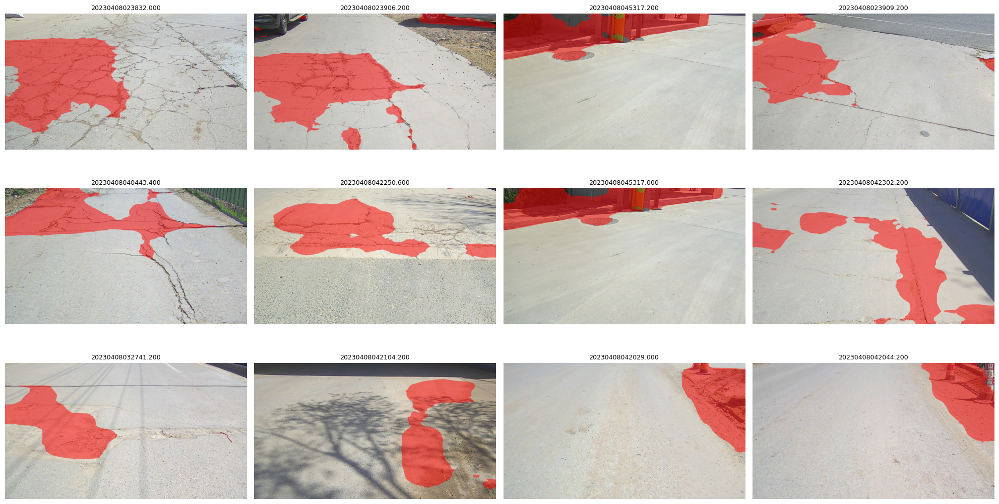

Copy the stems of frames with REAL potholes into ACCEPTED_IDS in the next cell.


In [37]:
MIN_COMP_PX = 2000                      # ignore tiny components (full-resolution pixels)
PROB_DIR = RES / "rsrd_prob"; PROB_DIR.mkdir(exist_ok=True)
proposer = load_model(PROP_TAG, CFG["seeds"][0])
cand = []
for stem in tqdm(FRAMES, desc="proposing masks"):
    prob = predict_prob_fullres(proposer, load_left(stem), DEVICE); mask = (prob > TUNED[PROP_TAG]["thr"]).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = [int(st[j, cv2.CC_STAT_AREA]) for j in range(1, n) if st[j, cv2.CC_STAT_AREA] >= MIN_COMP_PX]
    if areas:
        np.savez_compressed(PROB_DIR / f"{stem}.npz", prob=(prob * 255).astype(np.uint8)); cand.append((max(areas), stem))
cand.sort(reverse=True); print(f"{len(cand)} candidate frames out of {len(FRAMES)}")
show = [s for _, s in cand[:12]]
fig, ax = plt.subplots(3, 4, figsize=(20, 11))
for a, stem in zip(ax.ravel(), show):
    prob = np.load(PROB_DIR / f"{stem}.npz")["prob"] / 255.0; img = load_left(stem); mk_ = prob > TUNED[PROP_TAG]["thr"]
    img[mk_] = (0.5 * img[mk_] + 0.5 * np.array([255, 0, 0])).astype(np.uint8); a.imshow(img); a.set_title(stem, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()
print("Copy the stems of frames with REAL potholes into ACCEPTED_IDS in the next cell.")

8 frames with strict candidates (of 199 frames with any candidate)


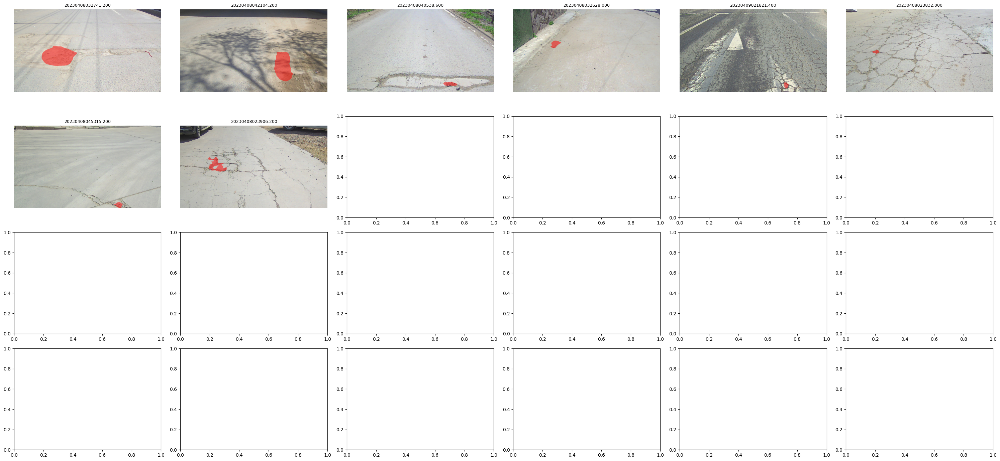

Put the stems of frames that contain a REAL pothole into ACCEPTED_IDS (next cell).


In [38]:
STRICT_THR = 0.8                 # high-confidence pixels only
MAX_COMP_FRAC = 0.05             # a pothole should not cover more than 5% of the frame
MIN_COMP_PX = 2000               # full-resolution pixels
ROAD_TOP = 0.40                  # ignore components centred in the top 40% of the frame

def strict_components(stem):
    prob = np.load(PROB_DIR / f"{stem}.npz")["prob"] / 255.0
    H, W = prob.shape
    n, lab, st, cen = cv2.connectedComponentsWithStats((prob > STRICT_THR).astype(np.uint8), connectivity=8)
    keep = [j for j in range(1, n) if MIN_COMP_PX <= st[j, cv2.CC_STAT_AREA] <= MAX_COMP_FRAC * H * W and cen[j][1] > ROAD_TOP * H]
    return prob, lab, keep

rank = []
for _, stem in cand:
    prob, lab, keep = strict_components(stem)
    if keep:
        rank.append((max(float(prob[lab == j].mean()) for j in keep), stem))
rank.sort(reverse=True)
print(f"{len(rank)} frames with strict candidates (of {len(cand)} frames with any candidate)")

show = [s for _, s in rank[:24]]
fig, ax = plt.subplots(4, 6, figsize=(30, 14))
for a, stem in zip(ax.ravel(), show):
    prob, lab, keep = strict_components(stem); img = load_left(stem)
    m_ = np.isin(lab, keep); img[m_] = (0.5 * img[m_] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    a.imshow(img); a.set_title(stem, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()
print("Put the stems of frames that contain a REAL pothole into ACCEPTED_IDS (next cell).")

0 20230408032741.200
1 20230408042104.200
2 20230408040538.600
3 20230408032628.000
4 20230409021821.400
5 20230408023832.000
6 20230408045315.200
7 20230408023906.200


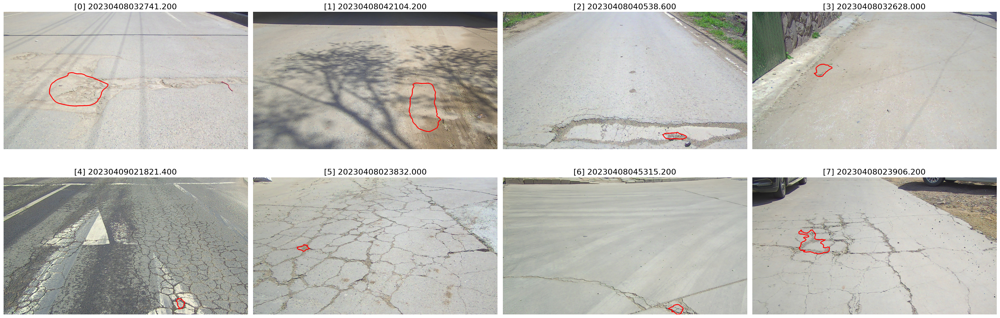

In [39]:
for i, s in enumerate(show[:8]):
    print(i, s)

fig, ax = plt.subplots(2, 4, figsize=(28, 10))
for i, (a, stem) in enumerate(zip(ax.ravel(), show[:8])):
    prob, lab, keep = strict_components(stem); img = load_left(stem)
    m_ = np.isin(lab, keep)
    cnts, _ = cv2.findContours(m_.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img, cnts, -1, (255, 0, 0), 6)       # red outline only, so you can see the road underneath
    a.imshow(img); a.set_title(f"[{i}] {stem}", fontsize=16); a.axis("off")
plt.tight_layout(); plt.show()

,dataset,sample_id,defect_id,mask_path,detection_score,depth_p95_m,area_m2,volume_m3,severity,measurement_status,valid_geometry_fraction,surface_fit_error_m,reason,disparity_source,stereo_method
0,RSRD,20230408032741.200,2,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.9217,NaN,NaN,NaN,None,unavailable,0.0249,NaN,too few valid depth pixels inside defect,reference,None
1,RSRD,20230408032741.200,2,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.9217,0.0201,0.4574,0.0045,medium,ok,1.0000,0.0036,,estimated,RAFT-Stereo (official princeton-vl code + pret...
2,RSRD,20230408042104.200,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8774,NaN,NaN,NaN,None,unavailable,0.0148,NaN,too few valid depth pixels inside defect,reference,None
3,RSRD,20230408042104.200,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8774,0.0019,0.2438,0.0001,None,uncertain,1.0000,0.0009,defect depth is within the road-plane fit noise,estimated,RAFT-Stereo (official princeton-vl code + pret...
4,RSRD,20230408040538.600,3,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8381,NaN,NaN,NaN,None,unavailable,0.0148,NaN,too few valid depth pixels inside defect,reference,None
5,RSRD,20230408040538.600,3,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8381,0.0062,0.0136,0.0001,None,uncertain,1.0000,0.0044,defect depth is within the road-plane fit noise,estimated,RAFT-Stereo (official princeton-vl code + pret...
6,RSRD,20230408032628.000,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8265,NaN,NaN,NaN,None,unavailable,0.0755,NaN,too few valid depth pixels inside defect,reference,None
7,RSRD,20230408032628.000,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8265,0.0079,0.0722,0.0003,None,uncertain,1.0000,0.0054,defect depth is within the road-plane fit noise,estimated,RAFT-Stereo (official princeton-vl code + pret...
8,RSRD,20230409021821.400,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8207,NaN,NaN,NaN,None,unavailable,0.0117,NaN,too few valid depth pixels inside defect,reference,None
9,RSRD,20230409021821.400,1,/kaggle/working/stereo_pothole/results/rsrd_ma...,0.8207,0.0006,0.0063,0.0000,None,uncertain,1.0000,0.0011,defect depth is within the road-plane fit noise,estimated,RAFT-Stereo (official princeton-vl code + pret...


{('estimated', 'uncertain'): 7, ('estimated', 'ok'): 1, ('reference', 'unavailable'): 8}


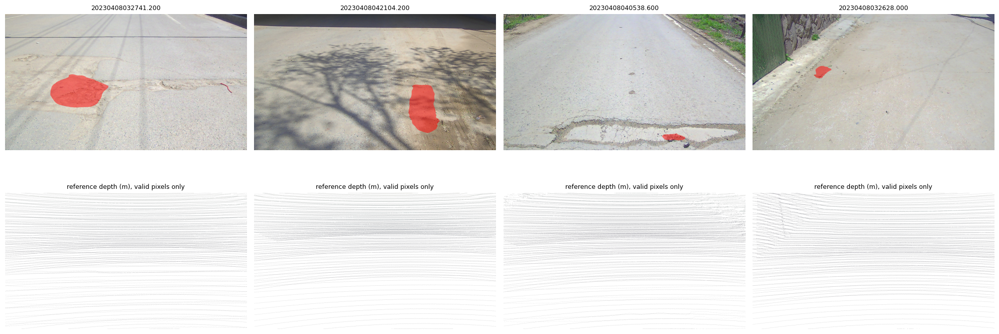

In [40]:
ACCEPTED_IDS = ["20230408032741.200","20230408042104.200","20230408040538.600","20230408032628.000","20230409021821.400","20230408023832.000","20230408045315.200","20230408023906.200"] 
assert ACCEPTED_IDS and "PUT_FRAME_TITLE_1" not in ACCEPTED_IDS, "Replace the placeholder titles with real frame names from the grid."
ensure_right(ACCEPTED_IDS)
MASK_DIR = RES / "rsrd_masks"; MASK_DIR.mkdir(exist_ok=True)
records, panels = [], []
for stem in ACCEPTED_IDS:
    prob, lab, keep = strict_components(stem)
    cv2.imwrite(str(MASK_DIR / f"{stem}.png"), (lab * np.isin(lab, keep)).astype(np.uint16))
    K, Bm, disp_ref = frame_geometry(stem)
    for source in ("reference", "estimated"):
        disp = disp_ref if source == "reference" else get_estimated_disparity(stem)
        depth = disparity_to_depth(disp, K[0, 0], Bm)
        for j in keep:
            comp = lab == j; r = measure_defect(depth, comp, K)
            records.append(dict(dataset="RSRD", sample_id=stem, defect_id=j, mask_path=str(MASK_DIR / f"{stem}.png"), detection_score=float(prob[comp].mean()),
                                **r, disparity_source=source, stereo_method=None if source == "reference" else STEREO_METHOD.get("name", "cached")))
        if source == "reference": panels.append((stem, np.where(np.isin(lab, keep), lab, 0), depth))

cols = ["dataset", "sample_id", "defect_id", "mask_path", "detection_score", "depth_p95_m", "area_m2", "volume_m3", "severity", "measurement_status",
        "valid_geometry_fraction", "surface_fit_error_m", "reason", "disparity_source", "stereo_method"]
pred = pd.DataFrame(records)[cols]; display(pred.round(4))
pred.to_csv(RES / "integrated_predictions.csv", index=False); pred.to_json(RES / "integrated_predictions.jsonl", orient="records", lines=True)
print(pred.groupby("disparity_source").measurement_status.value_counts().to_dict())
ok_both = pred[pred.measurement_status == "ok"].pivot_table(index=["sample_id", "defect_id"], columns="disparity_source", values="depth_p95_m")
if {"reference", "estimated"} <= set(ok_both.columns) and len(ok_both.dropna()):
    print("depth_p95 reference vs estimated (m), defects measurable with both:"); display(ok_both.dropna().round(4))

fig, ax = plt.subplots(2, min(4, len(panels)), figsize=(5 * min(4, len(panels)), 8), squeeze=False)
for k, (stem, lab, depth) in enumerate(panels[:4]):
    img = load_left(stem); img[lab > 0] = (0.5 * img[lab > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    ax[0, k].imshow(img); ax[0, k].set_title(stem, fontsize=9); ax[0, k].axis("off")
    ax[1, k].imshow(np.where(depth > 0, depth, np.nan), cmap="viridis"); ax[1, k].set_title("reference depth (m), valid pixels only", fontsize=9); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(RES / "integrated_examples.png", dpi=110); plt.show()

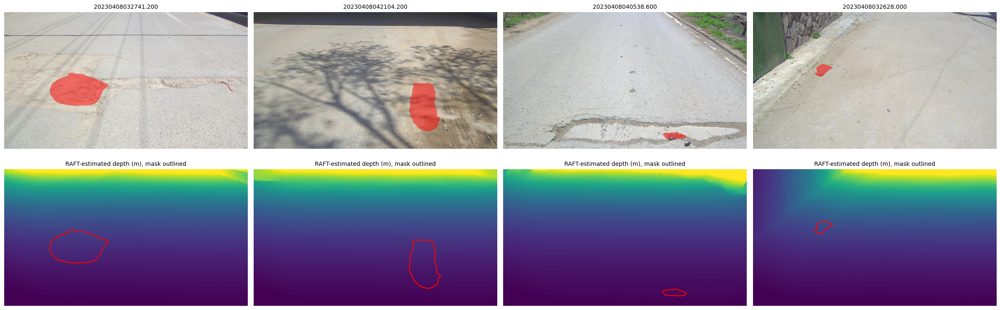

In [47]:
fig, ax = plt.subplots(2, 4, figsize=(24, 8))
for k, (stem, lab, _) in enumerate(panels[:4]):
    K, Bm, _ = frame_geometry(stem)
    dm = disparity_to_depth(get_estimated_disparity(stem), K[0, 0], Bm)
    img = load_left(stem); img[lab > 0] = (0.5 * img[lab > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    v = dm[dm > 0]
    ax[0, k].imshow(img); ax[0, k].set_title(stem, fontsize=10); ax[0, k].axis("off")
    ax[1, k].imshow(np.where(dm > 0, dm, np.nan), cmap="viridis", vmin=np.percentile(v, 2), vmax=np.percentile(v, 98))
    ax[1, k].contour(lab > 0, levels=[0.5], colors="red", linewidths=1.5)
    ax[1, k].set_title("RAFT-estimated depth (m), mask outlined", fontsize=10); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(RES / "integrated_examples_estimated_depth.png", dpi=110); plt.show()

## 12. Failure analysis and limitations

In [41]:
unavail = pred[pred.measurement_status != "ok"]
print("Defect measurements OK:", int((pred.measurement_status == "ok").sum()), "| unavailable (uncertain, NO severity):", len(unavail))
print(unavail.groupby("disparity_source").reason.value_counts().to_dict())
print("Severity counts (ASSUMED thresholds, not a standard):", pred.severity.value_counts(dropna=True).to_dict())
display(unavail[["sample_id", "defect_id", "disparity_source", "valid_geometry_fraction", "surface_fit_error_m", "reason"]])
print("TODO (report): explain each unavailable case (sparse depth / too few road pixels / bad plane fit / wrong mask / stereo error).")

Defect measurements OK: 1 | unavailable (uncertain, NO severity): 15
{('estimated', 'defect depth is within the road-plane fit noise'): 7, ('reference', 'too few valid depth pixels inside defect'): 8}
Severity counts (ASSUMED thresholds, not a standard): {'medium': 1}


,sample_id,defect_id,disparity_source,valid_geometry_fraction,surface_fit_error_m,reason
0,20230408032741.200,2,reference,0.024940,NaN,too few valid depth pixels inside defect
2,20230408042104.200,1,reference,0.014801,NaN,too few valid depth pixels inside defect
3,20230408042104.200,1,estimated,1.000000,0.000907,defect depth is within the road-plane fit noise
4,20230408040538.600,3,reference,0.014804,NaN,too few valid depth pixels inside defect
5,20230408040538.600,3,estimated,1.000000,0.004375,defect depth is within the road-plane fit noise
6,20230408032628.000,1,reference,0.075488,NaN,too few valid depth pixels inside defect
7,20230408032628.000,1,estimated,1.000000,0.005439,defect depth is within the road-plane fit noise
8,20230409021821.400,1,reference,0.011651,NaN,too few valid depth pixels inside defect
9,20230409021821.400,1,estimated,1.000000,0.001099,defect depth is within the road-plane fit noise
10,20230408023832.000,4,reference,0.028887,NaN,too few valid depth pixels inside defect


TODO (report): explain each unavailable case (sparse depth / too few road pixels / bad plane fit / wrong mask / stereo error).


**Limitations to state in the report**
- The proposed model is preliminary unless its gain holds across 3+ seeds and the `proposed_nocontrast` ablation (add it to `CFG["models_to_run"]`) is done; any gain over the baseline may be small or within seed variance. Report NCPR v1 as well.
- RSRD reference depth is sparse; pothole masks on RSRD come from a Pothole-600-trained model plus manual review (domain shift).
- RSRD calibration/rectification is taken from the dataset toolkit; the baseline is stored in mm.
- Severity thresholds (2 cm / 5 cm of p95 depth below the fitted road plane) are **assumed**, not validated against surveys.
- The stereo model is pretrained (official RAFT-Stereo); SGBM is only a fallback. State in the report which one was actually used. Estimated-disparity depth noise can exceed pothole depth at range.
- Connected components may merge touching defects. CARD and RELLIS-3D are not evaluated.

## Common sample manifest (required by the brief)

In [43]:
rows = []
for key, split in SPLITS.items():
    for n in sorted(p.name for p in (POTHOLE_DIR / split / "rgb").glob("*.png")):
        rows.append(dict(dataset="Pothole-600", sample_id=f"{split}/{Path(n).stem}", sequence_id="", left_image=str(POTHOLE_DIR / split / "rgb" / n), right_image="",
                         mask_path=str(POTHOLE_DIR / split / "label" / n), disparity_path="", depth_path="", calibration_path="", split=key, annotation_status="human_annotated"))
acc = set(globals().get("ACCEPTED_IDS", []))
for stem in FRAMES:
    rp = next((T / "right").glob(stem + ".*"), None) if (T / "right").exists() else None
    rows.append(dict(dataset="RSRD", sample_id=stem, sequence_id=stem[:8], left_image=str(next((T / "left").glob(stem + ".*"))), right_image=str(rp) if rp else "",
                     mask_path=str(RES / "rsrd_masks" / f"{stem}.png") if stem in acc else "", disparity_path=str(find("disparity", stem)),
                     depth_path=str(find("depth", stem)), calibration_path=calib_files[stem[:8]], split="test",
                     annotation_status="model_proposed_manually_reviewed" if stem in acc else "unlabeled"))
manifest = pd.DataFrame(rows); manifest.to_csv(DATA / "manifest.csv", index=False); print(manifest.groupby(["dataset", "split", "annotation_status"]).size())

dataset      split  annotation_status               
Pothole-600  test   human_annotated                     180
             train  human_annotated                     240
             val    human_annotated                     180
RSRD         test   model_proposed_manually_reviewed      8
                    unlabeled                           292
dtype: int64


## 11. Demo (Gradio)
Image only → overlay, **no** severity (with the reason). Left + right + calibration + baseline → estimated disparity and measurements. Image + metric depth `.npy` + calibration → measurements. Missing calibration, invalid depth or poor plane fit → explicit *unavailable* message. Set `LAUNCH_DEMO = True` to start it.

In [44]:
def make_demo(model, device, gr):
    """Gradio demo: image (segmentation only) or calibrated stereo pair / metric depth (measurements)."""
    def demo_fn(left, right, depth_file, fx, fy, cx, cy, baseline_m, thr):
        if left is None:
            return None, "Upload a road image."
        prob = predict_prob_fullres(model, left, device); mask = prob > thr
        ov = left.copy(); ov[mask] = (0.5 * ov[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        if mask.sum() == 0:
            return ov, "No pothole detected."
        n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
        comps = [j for j in range(1, n) if st[j, cv2.CC_STAT_AREA] >= 200]
        lines = [f"{len(comps)} defect region(s). Mean segmentation score {prob[mask].mean():.2f} (NOT a measurement confidence)."]
        if not all([fx, fy, cx, cy]):
            return ov, "\n".join(lines + ["Measurement UNAVAILABLE: no calibration supplied. No severity assigned."])
        K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1.0]])
        depth = None
        if right is not None and baseline_m:
            if right.shape != left.shape:
                return ov, "\n".join(lines + ["Measurement UNAVAILABLE: left and right images differ in size."])
            disp, method = estimate_disparity(left, right, device)
            depth = disparity_to_depth(disp, fx, baseline_m); lines.append("Depth source: " + method)
        elif depth_file is not None:
            depth = np.load(getattr(depth_file, "name", depth_file)); lines.append("Depth source: supplied .npy (metres)")
        if depth is None:
            return ov, "\n".join(lines + ["Measurement UNAVAILABLE: need a right image + baseline, or a metric depth map. No severity assigned."])
        if depth.shape != mask.shape:
            return ov, "\n".join(lines + [f"Measurement UNAVAILABLE: depth {depth.shape} does not match image {mask.shape}."])
        for j in comps:
            r = measure_defect(depth, lab == j, K)
            if r["measurement_status"] == "ok":
                lines.append(f"Defect {j}: depth_p95 {r['depth_p95_m']*100:.1f} cm | area {r['area_m2']:.3f} m2 | "
                             f"volume {r['volume_m3']*1000:.1f} L | severity {r['severity']} (assumed thresholds) | "
                             f"plane-fit error {r['surface_fit_error_m']*1000:.1f} mm")
            else:
                lines.append(f"Defect {j}: measurement UNAVAILABLE - {r['reason']}. No severity assigned.")
        return ov, "\n".join(lines)

    return gr.Interface(
        demo_fn,
        [gr.Image(type="numpy", label="Left / single road image"), gr.Image(type="numpy", label="Right image (optional, rectified)"),
         gr.File(label="Metric depth .npy in metres (optional)"),
         gr.Number(label="fx (px)"), gr.Number(label="fy (px)"), gr.Number(label="cx (px)"), gr.Number(label="cy (px)"),
         gr.Number(label="Baseline (m)"), gr.Slider(0.1, 0.9, 0.5, label="Mask threshold")],
        [gr.Image(label="Overlay"), gr.Textbox(label="Measurements / reasons", lines=8)],
        title="Pothole segmentation + geometric severity")


LAUNCH_DEMO = False
import gradio as gr
demo = make_demo(load_model(PROP_TAG, CFG["seeds"][0]), DEVICE, gr)
if LAUNCH_DEMO:
    demo.launch(share=True)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


## 13. Reproducibility and GitHub repository

In [49]:
subprocess.run("pip freeze > " + str(RES / "requirements_frozen.txt"), shell=True)
import transformers, torchvision
json.dump({"python": sys.version, "torch": torch.__version__, "torchvision": torchvision.__version__, "transformers": transformers.__version__,
           "segformer_weights": CFG["pretrained"], "stereo_model": "RAFT-Stereo (princeton-vl, raftstereo-middlebury.pth), SGBM fallback", "cfg": CFG},
          open(RES / "environment.json", "w"), indent=2)
shutil.make_archive("/kaggle/working/results_bundle", "zip", RES)
print("Saved:", sorted(p.name for p in RES.iterdir()))
print("Checkpoints are in", CKPT, "- do NOT commit them to git; give a download link in the README. Copy", DATA / "manifest.csv", "into the repo's data/ folder.")

Saved: ['audit_overlays.png', 'audit_pothole600.csv', 'config.json', 'environment.json', 'integrated_examples.png', 'integrated_examples_estimated_depth.png', 'integrated_predictions.csv', 'integrated_predictions.jsonl', 'per_image_iou_default_baseline_s42.npy', 'per_image_iou_default_baseline_s43.npy', 'per_image_iou_default_baseline_s44.npy', 'per_image_iou_default_proposed_s42.npy', 'per_image_iou_default_proposed_s43.npy', 'per_image_iou_default_proposed_s44.npy', 'per_image_iou_tuned_baseline_s42.npy', 'per_image_iou_tuned_baseline_s43.npy', 'per_image_iou_tuned_baseline_s44.npy', 'per_image_iou_tuned_proposed_s42.npy', 'per_image_iou_tuned_proposed_s43.npy', 'per_image_iou_tuned_proposed_s44.npy', 'qualitative_segmentation.png', 'requirements_frozen.txt', 'rsrd_disp_est', 'rsrd_masks', 'rsrd_prob', 'rsrd_stereo_estimation_eval.csv', 'rsrd_unit_check.csv', 'segmentation_failures.png', 'segmentation_results.json', 'segmentation_runs.csv', 'segmentation_summary.csv', 'test_names.jso

In [52]:
EX = Path("/kaggle/working/extras"); EX.mkdir(exist_ok=True)
shutil.copy(DATA / "manifest.csv", EX / "manifest.csv")
for tag in ("baseline", "proposed"):
    shutil.copy(ckpt_path(tag, 42), EX / ckpt_path(tag, 42).name)
shutil.make_archive("/kaggle/working/extras", "zip", EX)
print(sorted(p.name for p in EX.iterdir()))

['baseline_ce_s42.pth', 'manifest.csv', 'proposed_ce_s42.pth']


## 14. Measured results vs assumptions
| Measured (from the logged runs above) | Assumed / design choice (not independently validated) |
|---|---|
| Pothole-600 test metrics per model and seed (mean ± std), parameter counts, inference time | Severity thresholds: 2 cm and 5 cm on p95 depth below the fitted road plane |
| RSRD unit/consistency check; stereo-estimation error vs reference on a few pairs | Quality thresholds: valid-depth fraction, plane-fit error ≤ 1 cm, minimum road points |
| Measurements on the manually reviewed subset (reference vs estimated disparity) | Volume = mean depth below plane × footprint area (approximation) |
| Val-tuned probability threshold and minimum region size | RSRD masks: model-proposed + manual review; segmentation score ≠ measurement confidence |